In [84]:
import torch
import torch.nn as nn
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from torchvision import transforms

In [85]:
from datasets import load_dataset # Hugging Face data

In [86]:
dataset = load_dataset("timm/oxford-iiit-pet")

In [87]:
idx = 0
image = dataset['train'][idx]['image']

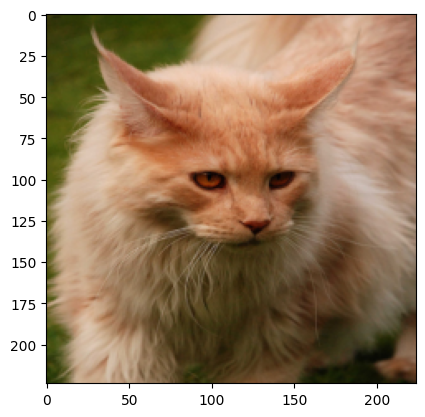

In [88]:
nimage = transforms.Resize((224, 224))( image)
plt.imshow(nimage)
plt.show()

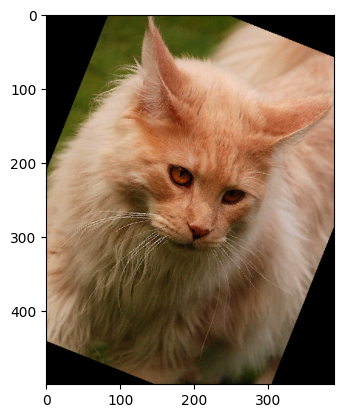

In [89]:
nimage = transforms.RandomRotation((-60, 45))(image)
plt.imshow(nimage)
plt.show()

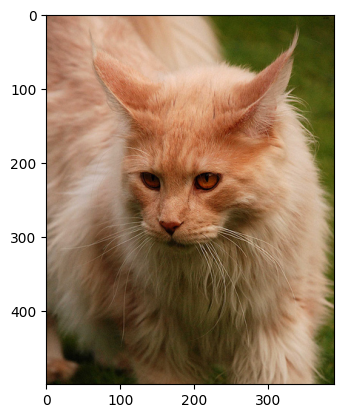

In [90]:
nimage = transforms.RandomHorizontalFlip(0.6)(image)
plt.imshow(nimage)
plt.show()

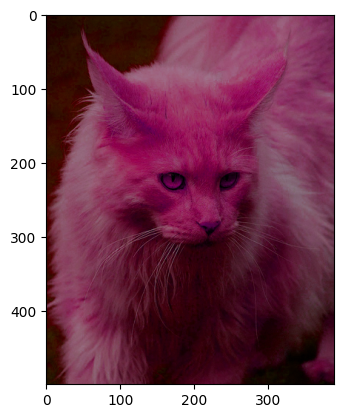

In [91]:
nimage = transforms.ColorJitter(1,1,1,0.5)(image)
plt.imshow(nimage)
plt.show()

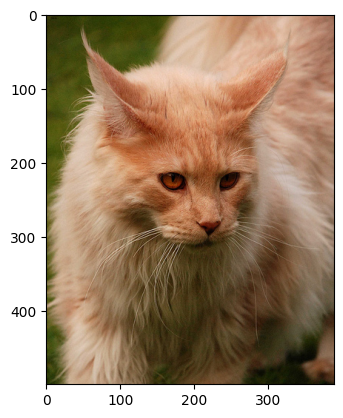

In [92]:
nimage = transforms.GaussianBlur(1,(30.7, 50.3))(image)
plt.imshow(nimage)
plt.show()

In [104]:
image_tensor = transforms.ToTensor()(image)

In [105]:
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]
image_tensor_norm = transforms.Normalize(mean,std)(image_tensor)
print(image_tensor_norm)

tensor([[[-0.9020, -0.9363, -1.0733,  ...,  0.7419,  0.7591,  0.8276],
         [-1.0219, -1.0390, -1.1075,  ...,  0.8104,  0.7077,  0.6563],
         [-1.0390, -1.0048, -1.0733,  ...,  0.6734,  0.6221,  0.6049],
         ...,
         [-1.6042, -1.5014, -1.5528,  ..., -1.1589, -1.0562, -1.0733],
         [-1.5357, -1.6384, -1.4672,  ..., -1.3130, -1.2274, -1.2274],
         [-1.5870, -1.5185, -1.4158,  ..., -1.4843, -1.4329, -1.4158]],

        [[-0.8277, -0.8627, -1.0203,  ..., -0.0224, -0.0049,  0.0126],
         [-0.9328, -0.9503, -1.0203,  ...,  0.0476, -0.0574, -0.1099],
         [-0.9153, -0.8803, -1.0028,  ..., -0.0749, -0.1450, -0.1625],
         ...,
         [-1.2479, -1.1429, -1.1954,  ..., -1.3529, -1.2654, -1.2829],
         [-1.1779, -1.2829, -1.0903,  ..., -1.4055, -1.3529, -1.3529],
         [-1.2304, -1.1604, -1.0378,  ..., -1.5280, -1.4755, -1.4580]],

        [[-1.4559, -1.4733, -1.5779,  ..., -0.1661, -0.1487, -0.1138],
         [-1.5081, -1.4907, -1.5604,  ..., -0

In [106]:
for i in range(len(dataset['train'])):
    if dataset['train'][i]['image'].mode == 'RGBA':
        print(i)
        break

63


In [107]:
idx = 63
image = dataset['train'][idx]['image']

In [111]:
arr = np.asarray(image).astype(np.float32) / 255


/tmp/ipykernel_715/3414143339.py:1: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  nimage = transforms.Lambda(lambda image: Image.fromarray(np.uint8(255 * (


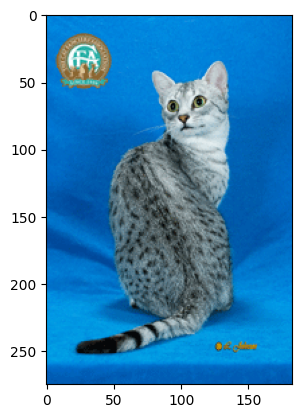

In [112]:
nimage = transforms.Lambda(lambda image: Image.fromarray(np.uint8(255 * ((arr)[:, :, 3:4] * (arr)[:, :, :3] + (1 - (arr)[:, :, 3:4]))), 'RGB'))(image)

plt.imshow(nimage)
plt.show()

In [137]:
pm = transforms.Lambda(lambda image: transforms.ToTensor()(image) * 2 - 1)

t = pm(nimage)
print(t.min(), t.max())


norm = transforms.Lambda(lambda t: (t - torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1))
                                        / torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1))

t_norm = norm(transforms.ToTensor()(nimage))
print(t_norm.shape)

tensor(-1.) tensor(0.9922)
torch.Size([3, 275, 183])


In [138]:
idx = 0
image = dataset['train'][idx]['image']
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

In [145]:
transform = transforms.Compose(
    [
        transforms.Lambda(lambda image: image if image.mode != 'RGBA' else Image.fromarray(np.uint8(255 * (
            (arr := np.asarray(image).astype(np.float32) / 255)[:, :, 3:4] * arr[:, :, :3] + (1 - arr[:, :, 3:4])
        )), 'RGB')),
        transforms.Resize((224, 224)),
        transforms.RandomHorizontalFlip(0.5),
        transforms.ColorJitter(1, 1, 1, 0.5),
        transforms.ToTensor(),
        transforms.Normalize(mean, std)
    ]
)

image_tensor = transform(image)
print(image_tensor.shape)

torch.Size([3, 224, 224])


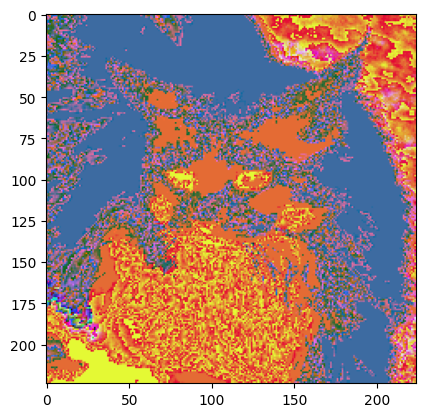

In [146]:


new_image = transforms.ToPILImage()(image_tensor)

plt.imshow(new_image)
plt.show()